In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Data loading and overview

In [2]:
cols = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach',
        'exang','oldpeak','slope','ca','thal','num']

In [3]:
frames = []

for src in ['cleveland', 'hungarian', 'switzerland', 'va']:
    d = pd.read_csv(f'../data/processed.{src}.data', names=cols, na_values='?')
    d['source'] = src
    frames.append(d)

df_raw = pd.concat(frames, ignore_index=True)

In [4]:
num_cols = ['age','trestbps','chol','thalach','oldpeak']
cat_cols = ['sex','cp','fbs','restecg','exang','slope','ca','thal']

In [5]:
print(df_raw.shape)

(920, 15)


In [6]:
print('Duplicates', df_raw.duplicated().sum())

Duplicates 2


In [7]:
os.makedirs('../reports/figures/eda', exist_ok=True)

## Data cleansing

In [8]:
df = df_raw.drop_duplicates().copy()

In [9]:
df.loc[df['trestbps'] == 0, 'trestbps'] = np.nan

In [10]:
df.loc[df['chol'] == 0, 'chol'] = np.nan

## Target Value

In [11]:
df['target'] = (df['num'] > 0).astype(int)

## Class balance

In [12]:
print(df['num'].value_counts(normalize=True).sort_index().round(3))
## Rozkład multilabel: niezbalansowany

num
0    0.447
1    0.289
2    0.118
3    0.117
4    0.031
Name: proportion, dtype: float64


In [13]:
print(df['target'].value_counts(normalize=True).round(3))
## Rozkład binarny: zbalansowany

target
1    0.553
0    0.447
Name: proportion, dtype: float64


In [14]:
print(pd.crosstab(df['source'], df['target'], normalize='index').round(3))
# Rozkład wg ośrodka

target           0      1
source                   
cleveland    0.541  0.459
hungarian    0.638  0.362
switzerland  0.065  0.935
va           0.256  0.744


## Missing values

In [15]:
missing = pd.DataFrame({
'missing': df[cols].isna().sum(),
'percent': (df[cols].isna().mean() * 100).round(1),
}).sort_values('missing', ascending=False)

In [16]:
# Missing values after cleansing
print(missing[missing['missing'] > 0])

          missing  percent
ca            609     66.3
thal          484     52.7
slope         307     33.4
chol          201     21.9
fbs            90      9.8
oldpeak        62      6.8
trestbps       60      6.5
thalach        55      6.0
exang          55      6.0
restecg         2      0.2


In [17]:
# Total missing values
total_missing = df[cols].isna().sum().sum()
print(total_missing)
print(total_missing / df[cols].size)

1925
0.14978213507625274


In [18]:
# Are missing values related to target

for c in ['ca', 'thal', 'slope', 'chol']:
    tab = pd.crosstab(df[c].isna(), df['target'], normalize='index')
    print(f'{c}: % of ill when missing = {tab.loc[True, 1]:.3f}, '
    f'% of illwhen exists = {tab.loc[False, 1]:.3f}')

ca: % of ill when missing = 0.598, % of illwhen exists = 0.466
thal: % of ill when missing = 0.539, % of illwhen exists = 0.569
slope: % of ill when missing = 0.375, % of illwhen exists = 0.643
chol: % of ill when missing = 0.811, % of illwhen exists = 0.481


## Statistics

In [19]:
desc = df[num_cols].describe().T

In [20]:
desc['skew'] = df[num_cols].skew()

In [21]:
desc['kurtosis'] = df[num_cols].kurtosis()

In [22]:
desc['missing_%'] = (df[num_cols].isna().mean() * 100).round(1)

In [23]:
print(desc.round(2))

          count    mean    std   min    25%    50%    75%    max  skew  \
age       918.0   53.51   9.43  28.0   47.0   54.0   60.0   77.0 -0.20   
trestbps  858.0  132.29  18.53  80.0  120.0  130.0  140.0  200.0  0.63   
chol      717.0  246.87  58.56  85.0  210.0  240.0  277.0  603.0  1.31   
thalach   863.0  137.54  25.94  60.0  120.0  140.0  157.0  202.0 -0.21   
oldpeak   856.0    0.88   1.09  -2.6    0.0    0.5    1.5    6.2  1.04   

          kurtosis  missing_%  
age          -0.39        0.0  
trestbps      0.64        6.5  
chol          4.76       21.9  
thalach      -0.48        6.0  
oldpeak       1.12        6.8  


## Distributions

### Numerical Distributions

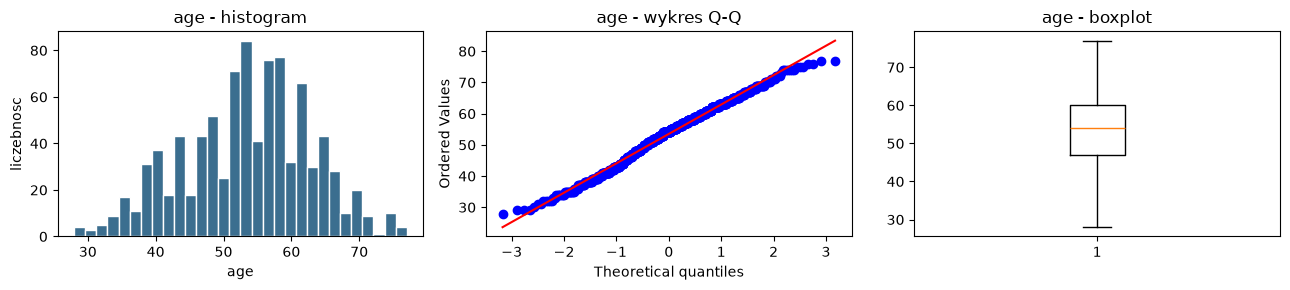

age: n=918, skosnosc=-0.20, kurtoza=-0.39


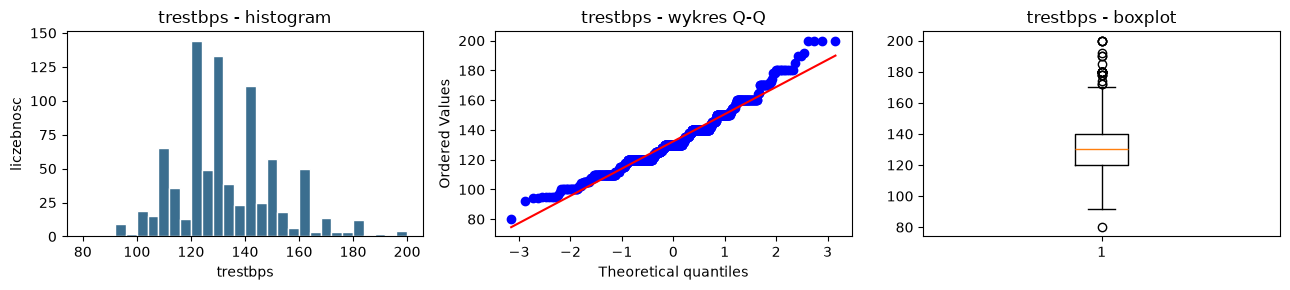

trestbps: n=858, skosnosc=0.63, kurtoza=0.64


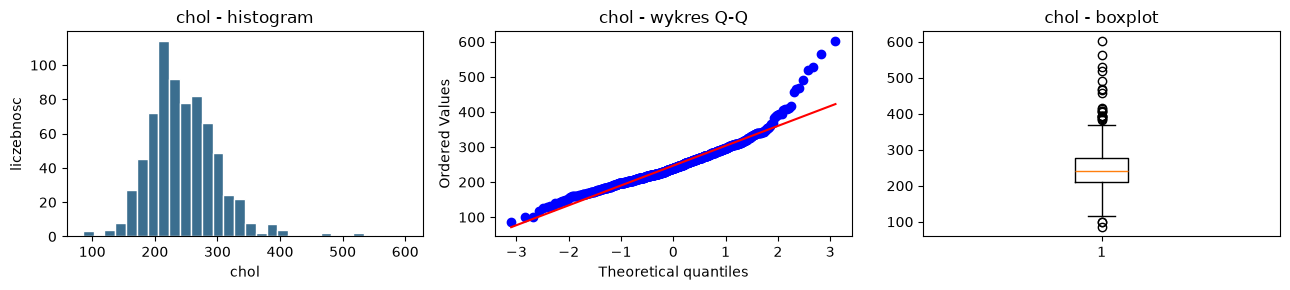

chol: n=717, skosnosc=1.31, kurtoza=4.76


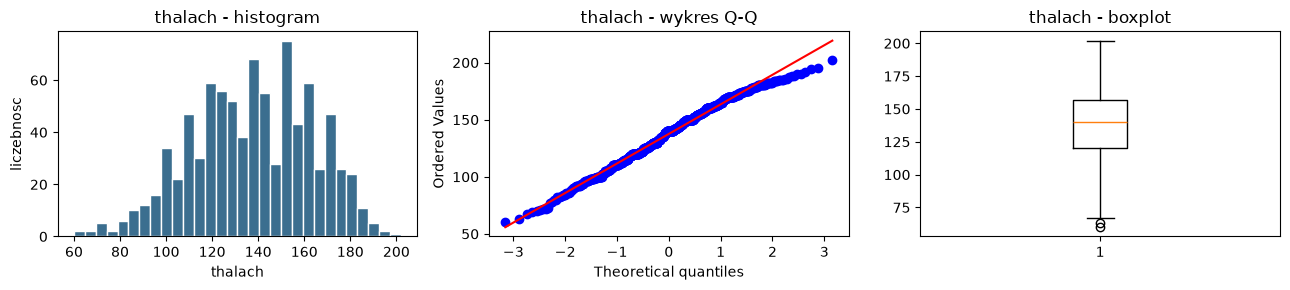

thalach: n=863, skosnosc=-0.21, kurtoza=-0.48


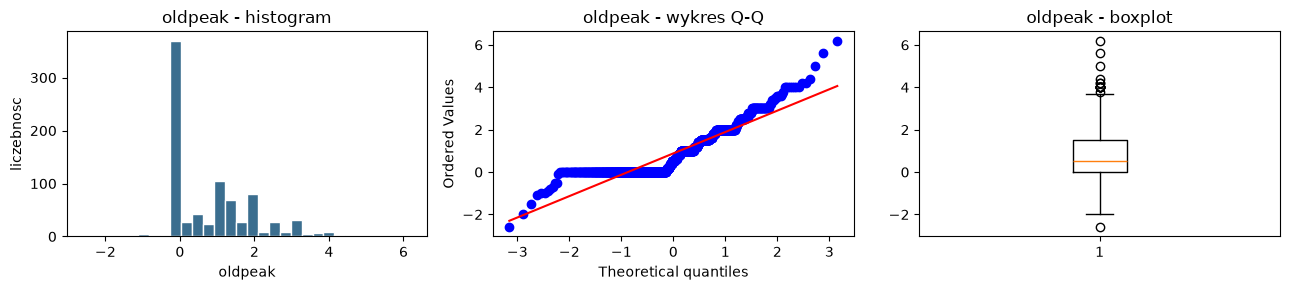

oldpeak: n=856, skosnosc=1.04, kurtoza=1.12


In [24]:
for c in num_cols:
    x = df[c].dropna()
    fig, ax = plt.subplots(1, 3, figsize=(13, 3))
    ax[0].hist(x, bins=30, color='#3b6e8f', edgecolor='white')
    ax[0].set_title(f'{c} - histogram')
    ax[0].set_xlabel(c)
    ax[0].set_ylabel('liczebnosc')
    stats.probplot(x, plot=ax[1])
    ax[1].set_title(f'{c} - wykres Q-Q')
    ax[2].boxplot(x)
    ax[2].set_title(f'{c} - boxplot')
    plt.tight_layout()
    plt.savefig(f'../reports/figures/eda/num_{c}.pdf', bbox_inches='tight')
    plt.show()
    print(f'{c}: n={len(x)}, skosnosc={x.skew():.2f}, 'f'kurtoza={x.kurtosis():.2f}')


### Categorical Distributions

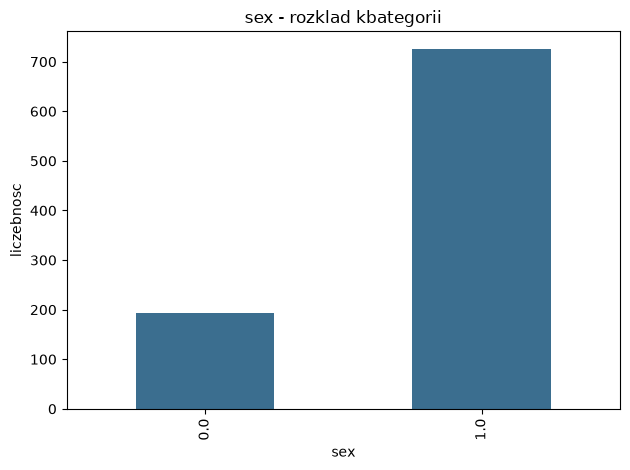

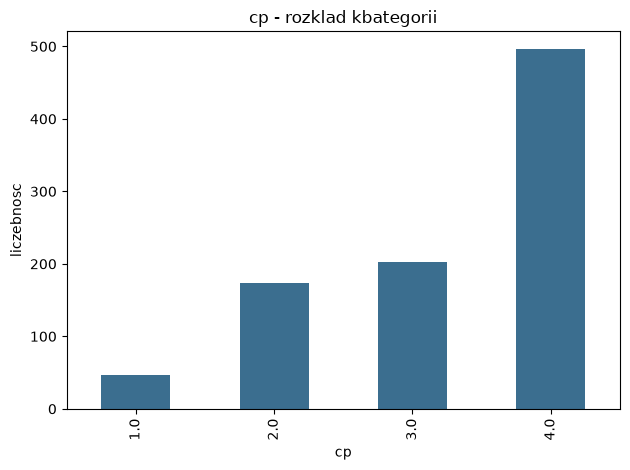

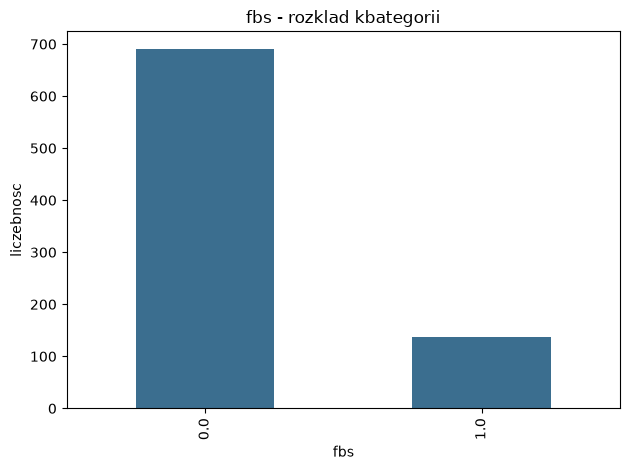

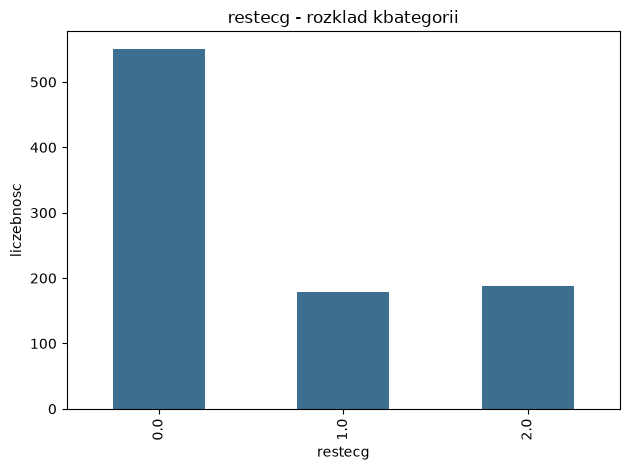

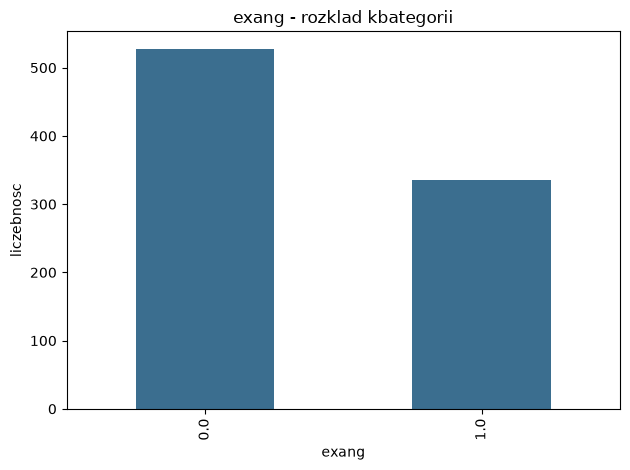

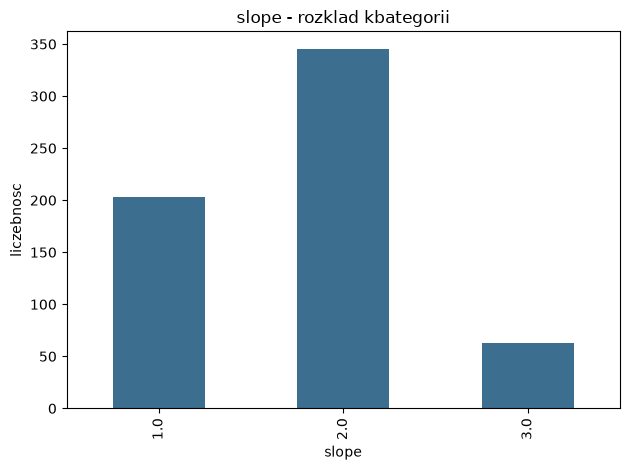

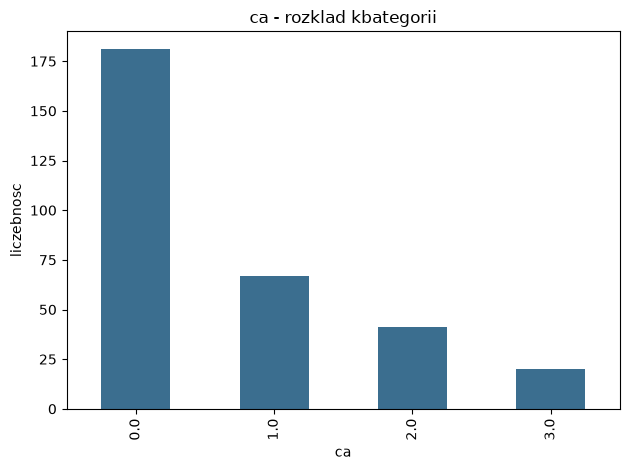

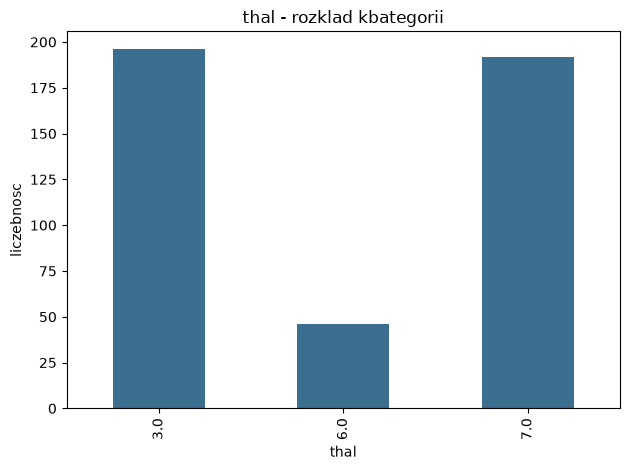

In [25]:
for c in cat_cols:
    df[c].value_counts().sort_index().plot.bar(
        title=f'{c} - rozklad kbategorii', color='#3b6e8f')
    plt.ylabel('liczebnosc')
    plt.tight_layout()
    plt.show()

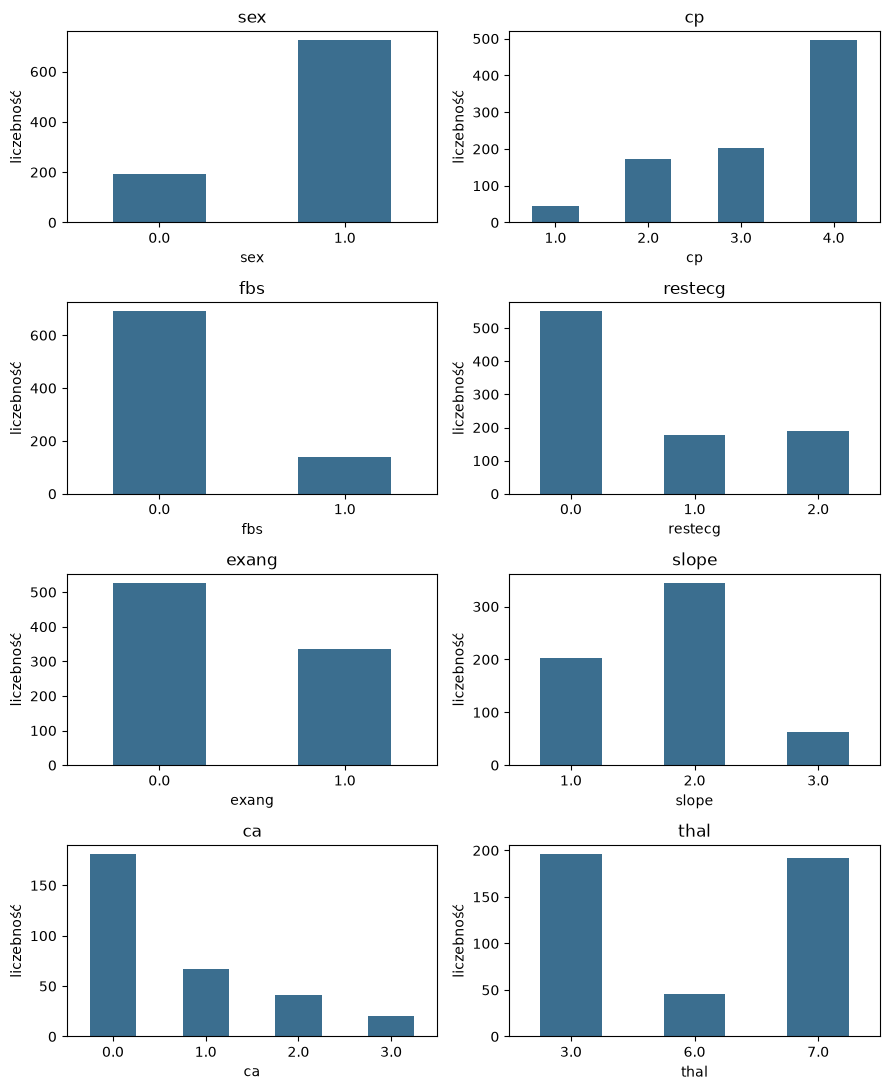

In [42]:
fig, axes = plt.subplots(4, 2, figsize=(9, 11))
for ax, c in zip(axes.flat, cat_cols):
    df[c].value_counts().sort_index().plot.bar(ax=ax, color='#3b6e8f')
    ax.set_title(c)
    ax.set_ylabel('liczebność')
    ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig('../reports/figures/eda/cat_wszystkie.pdf', bbox_inches='tight')
plt.show()

In [26]:
for c in cat_cols:
    vc = df[c].value_counts().sort_index()
    print(f'{c}: n={vc.sum()}, {vc.to_dict()}, '
          f'max_udzial={vc.max()/vc.sum():.1%}')

sex: n=918, {0.0: 193, 1.0: 725}, max_udzial=79.0%
cp: n=918, {1.0: 46, 2.0: 173, 3.0: 203, 4.0: 496}, max_udzial=54.0%
fbs: n=828, {0.0: 690, 1.0: 138}, max_udzial=83.3%
restecg: n=916, {0.0: 550, 1.0: 178, 2.0: 188}, max_udzial=60.0%
exang: n=863, {0.0: 527, 1.0: 336}, max_udzial=61.1%
slope: n=611, {1.0: 203, 2.0: 345, 3.0: 63}, max_udzial=56.5%
ca: n=309, {0.0: 181, 1.0: 67, 2.0: 41, 3.0: 20}, max_udzial=58.6%
thal: n=434, {3.0: 196, 6.0: 46, 7.0: 192}, max_udzial=45.2%


In [27]:
from scipy.stats import chisquare

print(c, chisquare(vc).pvalue)

thal 1.1725445230107813e-22


## Preprocessing

In [28]:
feat = num_cols + cat_cols

In [29]:
X = df[feat]
y = df['target']

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [31]:
num = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
bin = ['sex', 'fbs', 'exang']
nom = ['cp', 'restecg', 'thal']
ord = ['slope', 'ca']

In [32]:
num_pipeline = Pipeline([
('imp', SimpleImputer(strategy='median', add_indicator=True)),
('sc', StandardScaler()),
])

In [33]:
bin_pipeline = Pipeline([
('imp', SimpleImputer(strategy='most_frequent')),
])

In [34]:
nom_pipeline = Pipeline([
('imp', SimpleImputer(strategy='constant', fill_value=-1)),
('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

In [35]:
ord_pipeline = Pipeline([
('imp', SimpleImputer(strategy='median', add_indicator=True)),
('sc', StandardScaler()),
])

In [36]:
pre = ColumnTransformer([
('num', num_pipeline, num),
('bin', bin_pipeline, bin),
('nom', nom_pipeline, nom),
('ord', ord_pipeline, ord),
])

In [37]:
pre.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

## Baseline

In [38]:
models = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'LogReg': LogisticRegression(max_iter=2000,
        random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=300,
        random_state=42),
}

In [39]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [40]:
wyniki = []
for nazwa, clf in models.items():
    pipe = Pipeline([('pre', pre), ('clf', clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    if hasattr(clf, 'predict_proba'):
        auc_te = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
    else:
        auc_te = np.nan
    acc_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
    auc_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')
    wyniki.append({
        'model': nazwa,
        'acc_test': (y_pred == y_test).mean(),
        'auc_test': auc_te,
        'acc_cv': f'{acc_cv.mean():.3f} +/- {acc_cv.std():.3f}',
        'auc_cv': f'{auc_cv.mean():.3f} +/- {auc_cv.std():.3f}',
    })

    print(f'\n===== {nazwa} =====')
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred,
    target_names=['zdrowy', 'chory'],
    zero_division=0))


===== Dummy =====
[[  0  82]
 [  0 102]]
              precision    recall  f1-score   support

      zdrowy       0.00      0.00      0.00        82
       chory       0.55      1.00      0.71       102

    accuracy                           0.55       184
   macro avg       0.28      0.50      0.36       184
weighted avg       0.31      0.55      0.40       184


===== LogReg =====
[[66 16]
 [14 88]]
              precision    recall  f1-score   support

      zdrowy       0.82      0.80      0.81        82
       chory       0.85      0.86      0.85       102

    accuracy                           0.84       184
   macro avg       0.84      0.83      0.83       184
weighted avg       0.84      0.84      0.84       184


===== RandomForest =====
[[66 16]
 [15 87]]
              precision    recall  f1-score   support

      zdrowy       0.81      0.80      0.81        82
       chory       0.84      0.85      0.85       102

    accuracy                           0.83       184
  

In [41]:
print('\n--- podsumowanie ---')
print(pd.DataFrame(wyniki).round(3).to_string(index=False))


--- podsumowanie ---
       model  acc_test  auc_test          acc_cv          auc_cv
       Dummy     0.554     0.500 0.553 +/- 0.003 0.500 +/- 0.000
      LogReg     0.837     0.931 0.822 +/- 0.056 0.885 +/- 0.051
RandomForest     0.832     0.922 0.819 +/- 0.049 0.880 +/- 0.050
